# Tech Challenge - Fase 1

Case NPS Preditivo
Tech Challenge é o projeto que englobará os conhecimentos obtidos em todas
as disciplinas da fase. Esta é uma atividade que, em princípio, deve ser desenvolvida em grupo.É importante atentar-se ao prazo de entrega, pois trata-se de uma atividade obrigatória, uma vez que sua pontuação se refere a 90% da nota final.


Com o crescimento acelerado do e-commerce nacional, temos o cenário de
uma empresa que passou a lidar com um volume cada vez maior de pedidos, entregas
e interações com clientes. Esse crescimento trouxe ganhos importantes de escala,
mas também revelou desafios relevantes na experiência do cliente, especialmente
refletidos na alta variabilidade do Net Promoter Score (NPS) entre diferentes perfis de consumidores. A área de Experiência do Cliente percebeu que, mesmo com
indicadores operacionais aparentemente semelhantes, alguns clientes se tornam
promotores da marca, enquanto outros se tornam detratores.


Essa diferença levanta uma questão central para o negócio: quais fatores
operacionais realmente influenciam a satisfação do cliente e como a empresa
pode agir de forma proativa para melhorar a experiência antes mesmo da
aplicação da pesquisa de NPS?


Atualmente, o NPS é coletado apenas após o encerramento da jornada de
compra, o que limita a capacidade da empresa de antecipar problemas, priorizar
ações corretivas e atuar de forma preventiva. Nesse contexto, surge a necessidade
de transformar dados operacionais, como informações de pedidos, logística e
atendimento, em insights acionáveis, capazes de orientar decisões estratégicas e
operacionais.

## Introdução

- Definição de libs

- Leitura de csv

- Análise inicial de tamanho, tipos de dados e possíveis erros do dataframe

In [3]:
#Libs

import pandas as pd
import numpy as np

#libs gráficas
import plotly.express as px
import seaborn as sns
import matplotlib.pyplot as plt

#Avisos
import warnings
warnings.filterwarnings('ignore')

In [4]:
df = pd.read_csv("desafio_nps_fase_1.csv")
df.head()

,customer_id,customer_age,customer_region,customer_tenure_months,order_id,order_value,items_quantity,discount_value,payment_installments,delivery_time_days,delivery_delay_days,freight_value,delivery_attempts,customer_service_contacts,resolution_time_days,nps_score,repeat_purchase_30d,complaints_count,csat_internal_score
0,1,63,Nordeste,14,50001,139.73,4,39.35,4,2,2,55.53,3,0,4,6.9,0,3,6.5
1,2,20,Sul,1,50002,458.95,2,9.51,10,6,4,28.23,3,0,10,2.4,0,3,0.0
2,3,46,Nordeste,111,50003,507.06,5,42.82,6,6,1,40.99,1,4,5,4.8,0,7,1.5
3,4,52,Centro-Oeste,117,50004,302.19,2,19.58,9,5,2,35.24,3,1,11,5.9,0,4,0.3
4,5,56,Norte,50,50005,253.06,1,29.37,11,13,1,39.32,1,1,0,6.1,0,3,7.9


In [5]:
df.columns

Index(['customer_id', 'customer_age', 'customer_region',
       'customer_tenure_months', 'order_id', 'order_value', 'items_quantity',
       'discount_value', 'payment_installments', 'delivery_time_days',
       'delivery_delay_days', 'freight_value', 'delivery_attempts',
       'customer_service_contacts', 'resolution_time_days', 'nps_score',
       'repeat_purchase_30d', 'complaints_count', 'csat_internal_score'],
      dtype='object')

In [6]:
df.shape

(2500, 19)

In [7]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2500 entries, 0 to 2499
Data columns (total 19 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   customer_id                2500 non-null   int64  
 1   customer_age               2500 non-null   int64  
 2   customer_region            2500 non-null   object 
 3   customer_tenure_months     2500 non-null   int64  
 4   order_id                   2500 non-null   int64  
 5   order_value                2500 non-null   float64
 6   items_quantity             2500 non-null   int64  
 7   discount_value             2500 non-null   float64
 8   payment_installments       2500 non-null   int64  
 9   delivery_time_days         2500 non-null   int64  
 10  delivery_delay_days        2500 non-null   int64  
 11  freight_value              2500 non-null   float64
 12  delivery_attempts          2500 non-null   int64  
 13  customer_service_contacts  2500 non-null   int64

In [8]:
df.isnull().sum().sum()

np.int64(0)

In [9]:
df.duplicated().sum()

np.int64(0)

In [10]:
df.nunique()

,0
customer_id,2500
customer_age,52
customer_region,5
customer_tenure_months,119
order_id,2500
order_value,2457
items_quantity,6
discount_value,2050
payment_installments,11
delivery_time_days,13


In [11]:
# Resumo
print('Resumo:')
print("Linhas:", len(df))
print("Pedidos únicos:", df["order_id"].nunique())
print("Clientes únicos:", df["customer_id"].nunique())

print(
    "Pedidos repetidos:",
    df["order_id"].duplicated().sum()
)

print(
    "Clientes com mais de um pedido:",
    (df["customer_id"].value_counts() > 1).sum()
)

# NPS
print(f"Valor mínimo de NPS: {df['nps_score'].min()}")
print(f"Valor mínimo de NPS: {df['nps_score'].max()}")

Resumo:
Linhas: 2500
Pedidos únicos: 2500
Clientes únicos: 2500
Pedidos repetidos: 0
Clientes com mais de um pedido: 0
Valor mínimo de NPS: 0.0
Valor mínimo de NPS: 10.0


## Investigação da varíavel alvo e com outras varíaveis

In [12]:
df['nps_score'].value_counts().sum()

np.int64(2500)

Todos os clientes na base possuem NPS

In [13]:
#Análise descritiva no NPS

df['nps_score'].describe()

,nps_score
count,2500.000000
mean,4.378600
std,2.510229
min,0.000000
25%,2.600000
50%,4.400000
75%,6.100000
max,10.000000


In [14]:
fig = px.histogram(
    df,
    x="nps_score",
    nbins=30,
    title="Distribuição das Notas de NPS",
    labels={"nps_score": "Nota NPS", "count": "Frequência"}
)

fig.update_layout(
    yaxis_title="Frequência",
    showlegend=True
)

fig.show()

Distribuição do NPS em relação a sua frequência entre os valores 0 e 10

Resumo de varíaveis de avaliação e recompra

In [15]:
colunas = ['nps_score',	'repeat_purchase_30d',	'complaints_count',	'csat_internal_score']
pd.DataFrame({"Média": df[colunas].mean(), "Mediana": df[colunas].median()})

,Média,Mediana
nps_score,4.3786,4.4
repeat_purchase_30d,0.0872,0.0
complaints_count,4.1504,4.0
csat_internal_score,2.9416,2.8


Resumo de varíaveis de entrega

In [16]:
colunas = ['delivery_time_days',	'delivery_delay_days',	'freight_value',	'delivery_attempts',	'customer_service_contacts',	'resolution_time_days']
pd.DataFrame({"Média": df[colunas].mean(), "Mediana": df[colunas].median()})

,Média,Mediana
delivery_time_days,8.022000,8.0
delivery_delay_days,2.187200,2.0
freight_value,38.217016,38.5
delivery_attempts,2.005600,2.0
customer_service_contacts,1.519600,1.0
resolution_time_days,5.485600,6.0


Resumo de varíaveis de cliente

In [17]:
colunas = ['customer_age', 'customer_tenure_months']
pd.DataFrame({"Média": df[colunas].mean(), "Mediana": df[colunas].median()})

,Média,Mediana
customer_age,43.3960,43.0
customer_tenure_months,61.3224,62.0


Resumo de varíaveis de produto

In [18]:
colunas = ['order_id', 'order_value',	'items_quantity',	'discount_value',	'payment_installments']
pd.DataFrame({"Média": df[colunas].mean(), "Mediana": df[colunas].median()})

,Média,Mediana
order_id,51250.50000,51250.500
order_value,434.25974,375.515
items_quantity,3.47080,3.000
discount_value,29.74562,20.935
payment_installments,6.00400,6.000


# Validações em função do NPS Score


In [19]:
df.groupby('delivery_delay_days')['nps_score'].agg(
    ['count', 'mean', 'median', 'std']
)

,count,mean,median,std
delivery_delay_days,,,,
0,277,6.856679,6.80,2.013667
1,615,5.546179,5.50,2.184379
2,646,4.580186,4.60,2.039770
3,525,3.436762,3.40,1.998215
4,270,2.444444,2.30,1.831272
5,116,1.481034,1.25,1.598962
6,34,1.097059,0.70,1.243281
7,14,0.292857,0.00,0.415959
8,3,0.000000,0.00,0.000000


Validação de tempo de atraso em relação as notas de NPS


Nessa análise é possivel observar uma tendëncia onde menos dias de atrasos possuem notas de NPS mais altas

In [20]:
df.groupby('repeat_purchase_30d')['nps_score'].agg(
    ['count', 'mean', 'median', 'std']
)

,count,mean,median,std
repeat_purchase_30d,,,,
0,2282,3.936196,4.1,2.147671
1,218,9.009633,9.0,0.691521


Na análise de recompra após 30 dias também é possivel observar uma média de NPS mais alta

In [21]:
df.groupby('resolution_time_days')['nps_score'].agg(
    ['count', 'mean', 'median', 'std']
)

,count,mean,median,std
resolution_time_days,,,,
0,208,5.320192,5.45,2.497066
1,192,5.004167,5.00,2.586105
2,229,4.817904,5.00,2.453780
3,237,4.627848,4.60,2.661572
4,206,4.442233,4.30,2.450786
5,176,4.423295,4.45,2.342763
6,197,4.324365,4.50,2.560197
7,213,4.260563,4.40,2.457707
8,227,3.965639,3.80,2.379087


Na análise levando em consideração tempo total da compra, há uma leve tendëncia. por mais que as médias sejam baixas, de haver notas maiores de NPS em um tempo de resolução menor

In [61]:
df.groupby('customer_region')['nps_score'].agg(
    ['count', 'mean', 'median', 'max', 'min'])

,count,mean,median,max,min
customer_region,,,,,
Centro-Oeste,468,4.209829,4.2,10.0,0.0
Nordeste,485,4.421649,4.5,10.0,0.0
Norte,506,4.382609,4.5,10.0,0.0
Sudeste,520,4.373846,4.3,10.0,0.0
Sul,521,4.490979,4.5,10.0,0.0


Analisando as médias das regiöes não é possivel identificar padrões.

In [23]:
resumo_tentativas = (
    df.groupby('delivery_attempts')
    .agg(
        pedidos=('order_id', 'count'),
        nps_medio=('nps_score', 'mean'),
        nps_mediano=('nps_score', 'median'),
        atraso_mediano=('delivery_delay_days', 'median')
    )
    .sort_index()
)

display(resumo_tentativas.round(2))

,pedidos,nps_medio,nps_mediano,atraso_mediano
delivery_attempts,,,,
1,824,4.35,4.4,2.0
2,838,4.26,4.2,2.0
3,838,4.52,4.5,2.0


## Validação da matriz de correlação dos dados numéricos do DataFrame

In [62]:
numericas = ['customer_age', 'customer_tenure_months','order_value', 'items_quantity',
       'discount_value', 'payment_installments', 'delivery_time_days',
       'delivery_delay_days', 'freight_value', 'delivery_attempts',
       'customer_service_contacts', 'resolution_time_days', 'nps_score',
       'repeat_purchase_30d', 'complaints_count', 'csat_internal_score']
corr = df[numericas].corr(method="pearson")

# EXPERIMENTE:
# Troque method="pearson" por method="spearman". Que células mudam mais?

mascara = np.triu(np.ones_like(corr, dtype=bool), k=1)   # esconde o triângulo repetido
fig = px.imshow(corr.mask(mascara), text_auto=".2f", zmin=-1, zmax=1, aspect="auto",
                color_continuous_scale="RdBu_r")   # azul (−1) → branco (0) → vermelho (+1)
fig.update_traces(hovertemplate="%{y} × %{x}<br>correlação: %{z:.2f}<extra></extra>")
fig.update_layout(title="Matriz de correlação", height=600)
fig.show()


Podemos identificar correlações entre diversas variaveis

## Definição de uma classe para classificar o valor do NPS em uma variável qualitativa

In [25]:
def nps_class(df):
    if df['nps_score'] >= 9:
      return 'promotor'
    elif df['nps_score'] <= 6:
      return 'detrator'
    else:
      return 'passivo'

Os valores decimais ainda serão utilizados em calculos através do nps_score, a criação de uma classe serve para a separação de faixas de clientes de acordo com o Net Promoter Score, podendo assim, obter mais análises e resultados

In [26]:
df['nps_categoria'] = df.apply(nps_class, axis=1)
df.head()

,customer_id,customer_age,customer_region,customer_tenure_months,order_id,order_value,items_quantity,discount_value,payment_installments,delivery_time_days,delivery_delay_days,freight_value,delivery_attempts,customer_service_contacts,resolution_time_days,nps_score,repeat_purchase_30d,complaints_count,csat_internal_score,nps_categoria
0,1,63,Nordeste,14,50001,139.73,4,39.35,4,2,2,55.53,3,0,4,6.9,0,3,6.5,passivo
1,2,20,Sul,1,50002,458.95,2,9.51,10,6,4,28.23,3,0,10,2.4,0,3,0.0,detrator
2,3,46,Nordeste,111,50003,507.06,5,42.82,6,6,1,40.99,1,4,5,4.8,0,7,1.5,detrator
3,4,52,Centro-Oeste,117,50004,302.19,2,19.58,9,5,2,35.24,3,1,11,5.9,0,4,0.3,detrator
4,5,56,Norte,50,50005,253.06,1,29.37,11,13,1,39.32,1,1,0,6.1,0,3,7.9,passivo


In [27]:
promotores = df.query('nps_categoria == "promotor"')
promotores.head()

,customer_id,customer_age,customer_region,customer_tenure_months,order_id,order_value,items_quantity,discount_value,payment_installments,delivery_time_days,delivery_delay_days,freight_value,delivery_attempts,customer_service_contacts,resolution_time_days,nps_score,repeat_purchase_30d,complaints_count,csat_internal_score,nps_categoria
22,23,50,Sul,81,50023,578.34,3,28.67,5,2,0,38.37,1,0,2,10.0,1,0,8.6,promotor
26,27,21,Sudeste,26,50027,411.60,5,4.05,1,7,2,28.95,3,2,0,9.1,1,4,6.3,promotor
75,76,55,Nordeste,113,50076,261.42,4,28.92,3,9,1,16.29,3,1,10,9.6,1,3,2.0,promotor
99,100,21,Norte,36,50100,267.36,3,7.79,4,3,1,32.04,2,1,0,10.0,1,4,7.3,promotor
102,103,69,Nordeste,81,50103,70.41,6,18.87,5,4,2,49.50,2,0,10,9.4,1,2,1.8,promotor


In [28]:
df_nps = df[['nps_categoria', 'nps_score', "delivery_delay_days", 'repeat_purchase_30d']]
df_nps

,nps_categoria,nps_score,delivery_delay_days,repeat_purchase_30d
0,passivo,6.9,2,0
1,detrator,2.4,4,0
2,detrator,4.8,1,0
3,detrator,5.9,2,0
4,passivo,6.1,1,0
...,...,...,...,...
2495,detrator,3.7,3,0
2496,detrator,3.7,2,0
2497,passivo,7.4,2,0
2498,detrator,2.3,5,0


In [29]:
print(df_nps['nps_categoria'].value_counts())

porcentagem_nps_categoria = df_nps['nps_categoria'].value_counts(normalize=True) * 100
porcentagem_nps_categoria

nps_categoria
detrator    1851
passivo      539
promotor     110
Name: count, dtype: int64


,proportion
nps_categoria,
detrator,74.04
passivo,21.56
promotor,4.40


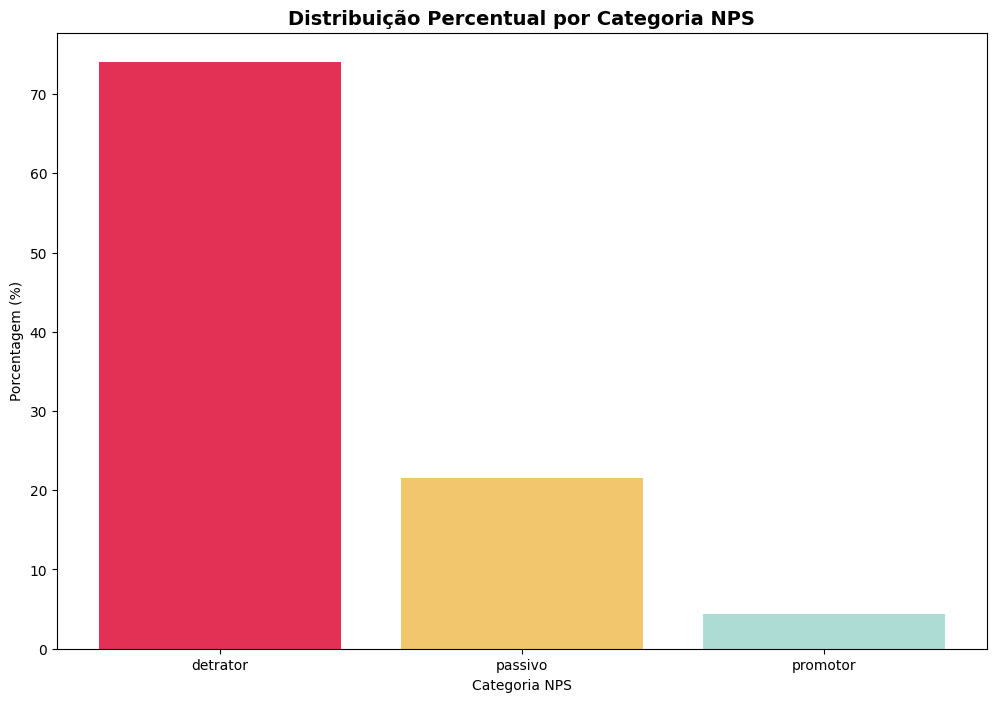

In [30]:
plt.figure(figsize = (12,8))

plt.bar(porcentagem_nps_categoria.index, porcentagem_nps_categoria, color=['#e23155', '#f2c66d', '#acdcd3'])

plt.title("Distribuição Percentual por Categoria NPS", fontsize=14, fontweight='bold')
plt.xlabel("Categoria NPS")
plt.ylabel("Porcentagem (%)")
plt.show()

Visualização da distribuição de NPS por classe de cliente

## Validação das principais correlações por Pearson x Spearman

TEMPO DE ENTREGA X NPS SCORE

In [31]:
corr_tempo_de_entrega_pearson = df[["nps_score", "delivery_time_days"]].corr()
corr_tempo_de_entrega_spearman = df[["nps_score", "delivery_time_days"]].corr(method="spearman")

print(corr_tempo_de_entrega_pearson)
print(corr_tempo_de_entrega_spearman)

                    nps_score  delivery_time_days
nps_score            1.000000            0.000925
delivery_time_days   0.000925            1.000000
                    nps_score  delivery_time_days
nps_score            1.000000            0.000299
delivery_time_days   0.000299            1.000000


Podemos validar que por ambos os métodos de correlação não existe correlação entre o tempo de entrega e o NPS

CSAT X NPS SCORE

In [32]:
corr_csat_pearson = df[["csat_internal_score", "nps_score"]].corr()
corr_csat_spearman = df[["csat_internal_score", "nps_score"]].corr(method="spearman")

print(corr_csat_pearson)
print(corr_csat_spearman)

                     csat_internal_score  nps_score
csat_internal_score             1.000000   0.563952
nps_score                       0.563952   1.000000
                     csat_internal_score  nps_score
csat_internal_score             1.000000   0.560886
nps_score                       0.560886   1.000000


Ambas as avaliações possuem uma correlação, o que faz sentido pois se uma nota é alta a outra não deve divergir muito

In [33]:
corr_temmpo_de_resolucao_pearson = df[["csat_internal_score", "resolution_time_days"]].corr()
corr_temmpo_de_resolucao_spearman = df[["csat_internal_score", "resolution_time_days"]].corr(method="spearman")

print(corr_temmpo_de_resolucao_pearson)
print(corr_temmpo_de_resolucao_spearman)

                      csat_internal_score  resolution_time_days
csat_internal_score              1.000000             -0.738452
resolution_time_days            -0.738452              1.000000
                      csat_internal_score  resolution_time_days
csat_internal_score              1.000000             -0.744439
resolution_time_days            -0.744439              1.000000


Aqui temos um ponto interessante, a nota interna de CSAT possui alta correlacão negativa com o tempo de resolução, quando o tempo de resolução é menor, a nota CSAT tende a aumentar

In [34]:
fig = px.scatter(
    df,
    x="csat_internal_score",
    y="resolution_time_days",
    opacity=0.4,
    title="Relação entre Nota CSAT e Dias de Resolução do Pedido",
    labels={"csat_internal_score": "Nota do CSAT", "resolution_time_days": "Dias de Resolução"}
)

fig.update_layout(
    xaxis_title="Nota do CSAT",
    yaxis_title="Dias de Resolução do Pedido"
)

fig.show()

In [35]:
corr_tempo_de_entrega_pearson = df[["nps_score", "resolution_time_days"]].corr()
corr_tempo_de_entrega_spearman = df[["nps_score", "resolution_time_days"]].corr(method="spearman")

print(corr_tempo_de_entrega_pearson)
print(corr_tempo_de_entrega_spearman)

                      nps_score  resolution_time_days
nps_score              1.000000             -0.191392
resolution_time_days  -0.191392              1.000000
                      nps_score  resolution_time_days
nps_score               1.00000              -0.19033
resolution_time_days   -0.19033               1.00000


A correlação negativa com o nps_score é menor mas também existe

ATRASO NA ENTREGA X NPS SCORE

Nesse caso a correlação de pearson trouxe um correlação mais negativa, onde enquanto uma varíavel diminui a outra varíavel tende a crescer

In [36]:
corr_atraso_de_entrega_pearson = df[["nps_score", "delivery_delay_days"]].corr()
corr_atraso_de_entrega_spearman = df[["nps_score", "delivery_delay_days"]].corr(method="spearman")

print(corr_atraso_de_entrega_pearson)
print(corr_atraso_de_entrega_spearman)

                     nps_score  delivery_delay_days
nps_score              1.00000             -0.59726
delivery_delay_days   -0.59726              1.00000
                     nps_score  delivery_delay_days
nps_score             1.000000            -0.586217
delivery_delay_days  -0.586217             1.000000


In [37]:
df[["nps_score", "delivery_delay_days"]].corr()

,nps_score,delivery_delay_days
nps_score,1.00000,-0.59726
delivery_delay_days,-0.59726,1.00000


In [38]:
fig = px.scatter(
    df,
    x="nps_score",
    y="delivery_delay_days",
    opacity=0.4,
    title="Relação entre Nota NPS e Dias de Atraso na Entrega",
    labels={"nps_score": "Nota do NPS", "delivery_delay_days": "Dias de Atraso"}
)

fig.update_layout(
    xaxis_title="Nota do NPS",
    yaxis_title="Dias de Atraso na Entrega"
)

fig.show()

Na visualização é possivel observar os valores mais altos de NPS na parte inicial do gráfico, onde os dias de atraso são menores ou inexistentes

## Analisando como o atraso no tempo de entrega afeta a nota do NPS

In [39]:
df["delivery_delay_days"].value_counts().sort_index()

,count
delivery_delay_days,
0,277
1,615
2,646
3,525
4,270
5,116
6,34
7,14
8,3


Ao validar a quantidade de casos por valor, podemos identificar que há menos casos nos valores de atraso mais alto, dessa forma, será feito um agrupamento dos valores por faixa de atraso

## Definindo uma classe para agrupar os dias de atraso na entrega em faixas de tempo

In [40]:
def atraso_entrega(df):
    if df['delivery_delay_days'] == 0:
      return 'No prazo/antecipada'
    elif df['delivery_delay_days'] <= 2:
      return '1–2 dias'
    elif df['delivery_delay_days'] <= 5:
      return '3–5 dias'
    else:
      return 'Mais de 5 dias'

In [41]:
df_nps['faixa_atraso'] = df_nps.apply(atraso_entrega, axis=1)
df.head()

def calcular_nps(df):
    promotores = (df["nps_score"] >= 9).mean() * 100
    detratores = (df["nps_score"] <= 6).mean() * 100

    return pd.Series({
        "Pedidos": len(df),
        "NPS": promotores - detratores,
        "Nota média": df["nps_score"].mean(),
        "% Detratores": detratores
    })

resumo_atraso = (
    df_nps.groupby("faixa_atraso", observed=True)
      .apply(calcular_nps, include_groups=False)
)

print(resumo_atraso.round(2))

porcentagem_atraso = df_nps['faixa_atraso'].value_counts(normalize=True) * 100
porcentagem_atraso

                     Pedidos     NPS  Nota média  % Detratores
faixa_atraso                                                  
1–2 dias              1261.0  -63.20        5.05         67.72
3–5 dias               911.0  -92.43        2.89         92.76
Mais de 5 dias          51.0 -100.00        0.81        100.00
No prazo/antecipada    277.0  -18.41        6.86         36.46


,proportion
faixa_atraso,
1–2 dias,50.44
3–5 dias,36.44
No prazo/antecipada,11.08
Mais de 5 dias,2.04


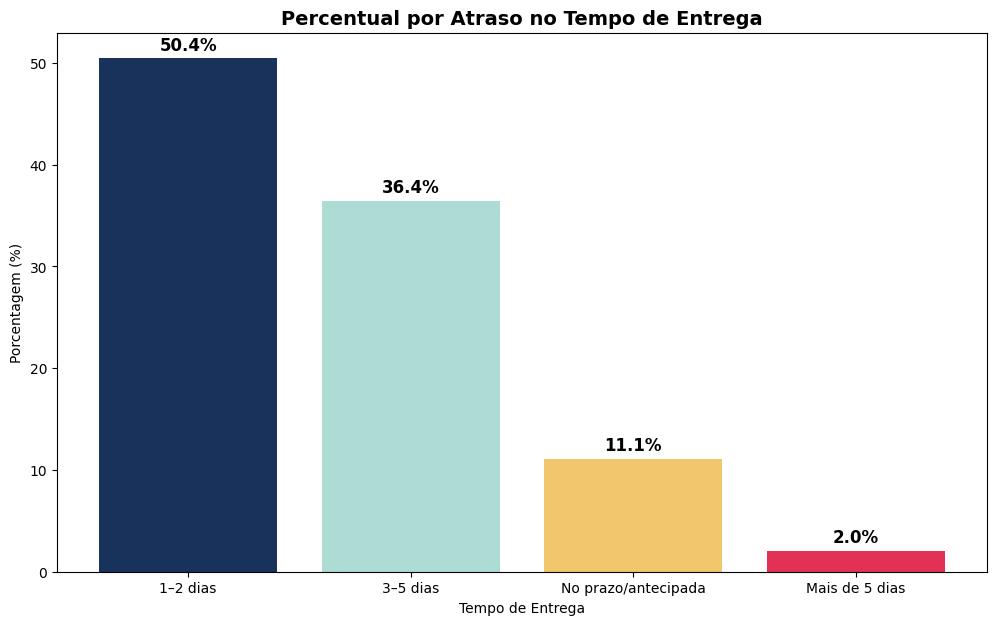

In [42]:
fig, ax = plt.subplots(figsize=(12, 7))

# As cores para as 4 categorias de atraso
cores_barras = ['#19325c', '#acdcd3', '#f2c66d','#e23155']

barras = ax.bar(porcentagem_atraso.index, porcentagem_atraso.values, color=cores_barras)
ax.bar_label(barras, fmt='%.1f%%', padding=3, fontsize=12, fontweight='bold')

plt.title("Percentual por Atraso no Tempo de Entrega", fontsize=14, fontweight='bold')
plt.xlabel("Tempo de Entrega")
plt.ylabel("Porcentagem (%)")
plt.show()

Acima a porcentagem de frequëncia para cada faixa de tempo em relação aos atrasos na entrega

In [43]:
print(df_nps['faixa_atraso'].value_counts())

faixa_atraso
1–2 dias               1261
3–5 dias                911
No prazo/antecipada     277
Mais de 5 dias           51
Name: count, dtype: int64


In [44]:
df_nps['faixa_atraso'].unique()

array(['1–2 dias', '3–5 dias', 'No prazo/antecipada', 'Mais de 5 dias'],
      dtype=object)

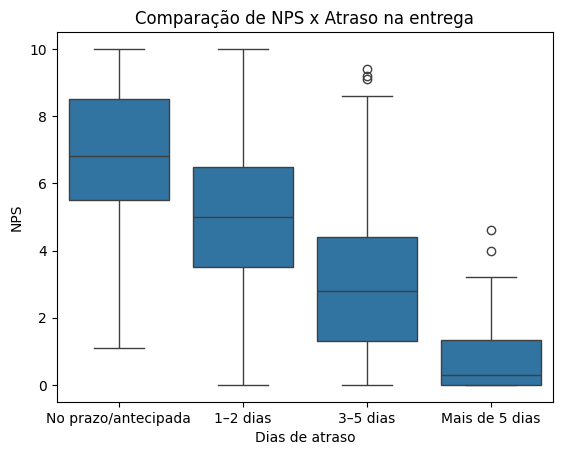

In [45]:
ordem = ['No prazo/antecipada', '1–2 dias', '3–5 dias', 'Mais de 5 dias']

sns.boxplot(y = df_nps['nps_score'], x = df_nps['faixa_atraso'], data = df, order = ordem)

plt.title("Comparação de NPS x Atraso na entrega")
plt.xlabel("Dias de atraso")
plt.ylabel("NPS")
plt.show()

Nesse boxplot podemos validar visualmente essa correlação negativa entre NPS x Atraso no tempo de entrega

Com essa análise podemos identificar que existe uma correlação entre os dias de atraso com a nota do NPS, quanto maior o atraso, existe uma tendëncia a uma menor nota de NPS

In [46]:
promotores_percentual = (df_nps["nps_score"] >= 9).mean() * 100
detratores_percentual = (df_nps["nps_score"] <= 6).mean() * 100

nps = promotores_percentual - detratores_percentual

print(f"% Promotores: {promotores_percentual:.2f}%")
print(f"% Detratores: {detratores_percentual:.2f}%")
print(f"NPS geral: {nps:.2f}")

% Promotores: 4.40%
% Detratores: 74.04%
NPS geral: -69.64


Nesse ponto podemos notar uma predominância de detratores no quadro geral de clientes

In [47]:
analise_atraso = pd.DataFrame(df_nps.groupby('faixa_atraso').agg(
        pedidos=('nps_score', 'count'),
        promotores=('nps_categoria', lambda x: (x == 'promotor').sum()),
        detratores=('nps_categoria', lambda x: (x == 'detrator').sum())
    )
)

analise_atraso['% promotores'] = (analise_atraso['promotores'] / analise_atraso['pedidos'] * 100
)

analise_atraso['% detratores'] = (analise_atraso['detratores'] / analise_atraso['pedidos'] * 100
)

analise_atraso['NPS'] = (
    analise_atraso['% promotores'] -
    analise_atraso['% detratores']
)

analise_atraso.round(2)

,pedidos,promotores,detratores,% promotores,% detratores,NPS
faixa_atraso,,,,,,
1–2 dias,1261,57,854,4.52,67.72,-63.20
3–5 dias,911,3,845,0.33,92.76,-92.43
Mais de 5 dias,51,0,51,0.00,100.00,-100.00
No prazo/antecipada,277,50,101,18.05,36.46,-18.41


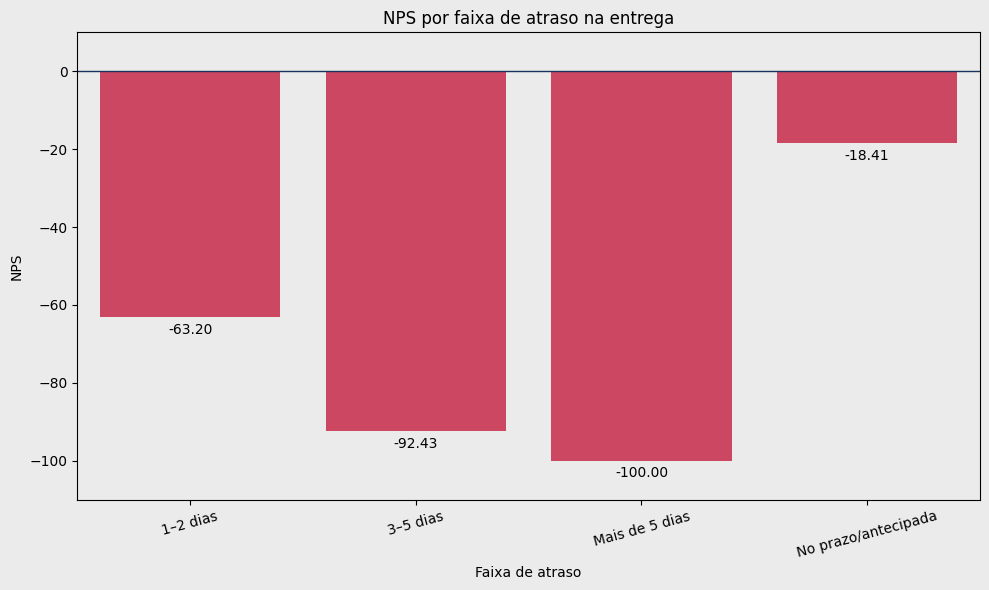

In [48]:
fig, ax = plt.subplots(figsize=(10, 6))

grafico = analise_atraso.reset_index()

sns.barplot(
    data=grafico,
    x='faixa_atraso',
    y='NPS',
    color='#e23155',
    errorbar=None,
    ax=ax,
)

ax.bar_label(ax.containers[0], fmt='%.2f', padding=4)
ax.axhline(0, color='#19325c', linewidth=1)

ax.set_title('NPS por faixa de atraso na entrega')
ax.set_xlabel('Faixa de atraso')
ax.set_ylabel('NPS')
ax.set_ylim(-110, 10)

fig.patch.set_facecolor('#ebebeb')
ax.set_facecolor('#ebebeb')
ax.tick_params(axis='x', rotation=15)

plt.tight_layout()
plt.show()

O objetivo dessa visualização é validar a degradação do NPS por faixa de atraso, na faixa de 3 - 5 dias de atraso a uma degradação de 92.43% de NPS, sendo um possivel ponto de ruptura para a expêriencia do cliente

In [49]:
analise_atraso = pd.DataFrame(df_nps.groupby('faixa_atraso').agg(
        pedidos=('nps_score', 'count'),
        promotores=('nps_categoria', lambda x: (x == 'promotor').sum()),
        detratores=('nps_categoria', lambda x: (x == 'detrator').sum())
    )
)

Recompra_30_dias_sim_nao
Não    2282
Sim     218
Name: count, dtype: int64
                          Pedidos    NPS  Nota média  % Detratores
Recompra_30_dias_sim_nao                                          
Não                        2282.0 -81.11        3.94         81.11
Sim                         218.0  50.46        9.01          0.00


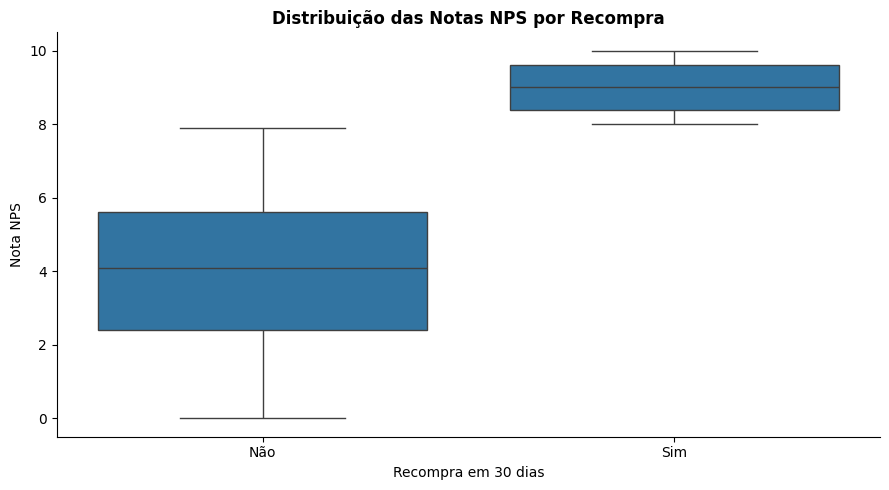

In [50]:
mapeamento = {0: "Não", 1: "Sim"}
df['Recompra_30_dias_sim_nao'] = df['repeat_purchase_30d'].map(mapeamento)

# Validar os valores presentes antes de interpretar o indicador
print(df["Recompra_30_dias_sim_nao"].value_counts())

# Resumo por recompra
resumo_recompra = (df.groupby("Recompra_30_dias_sim_nao").apply(calcular_nps))

print(resumo_recompra.round(2))

# Comparação de distribuição das notas
fig, ax = plt.subplots(figsize=(9, 5))

sns.boxplot(data=df, x="Recompra_30_dias_sim_nao", y="nps_score", ax=ax)

ax.set_title("Distribuição das Notas NPS por Recompra", fontweight="bold")
ax.set_xlabel("Recompra em 30 dias")
ax.set_ylabel("Nota NPS")
ax.spines[["top", "right"]].set_visible(False)

plt.tight_layout()
plt.show()

In [51]:
df_nps = df[['order_id', 'nps_categoria', 'nps_score', "delivery_delay_days", 'repeat_purchase_30d']]

taxa_recompra = (
    df_nps.groupby('nps_categoria').agg(
        pedidos=('order_id', 'count'),
        taxa_recompra=('repeat_purchase_30d', 'mean')
    )
)

taxa_recompra['taxa_recompra'] *= 100

display(taxa_recompra.round(2))

,pedidos,taxa_recompra
nps_categoria,,
detrator,1851,0.00
passivo,539,20.04
promotor,110,100.00


Na análise de recompra podemos validar que 100% dos promotores realizaram uma recompra após 30 dias, muito diferente dos detratores onde nenhum realizou a recompra.


Não podemos utilizar isso como regra ou causa, porém existem fortes tendências de um cliente que avalia com notas mais altas realize uma recompra.

## Validação do perfil de usuario detrator

In [52]:
df.groupby('customer_region')['complaints_count'].agg(
    ['count', 'sum'])

,count,sum
customer_region,,
Centro-Oeste,468,1955
Nordeste,485,2019
Norte,506,2080
Sudeste,520,2206
Sul,521,2116


In [53]:
df['faixa_atraso'] = df.apply(atraso_entrega, axis=1)

df.groupby('faixa_atraso')['complaints_count'].agg(
    ['count', 'sum'])

,count,sum
faixa_atraso,,
1–2 dias,1261,5278
3–5 dias,911,4041
Mais de 5 dias,51,238
No prazo/antecipada,277,819


In [54]:
import plotly.express as px

ordem_faixas = [
    'No prazo/antecipada',
    '1–2 dias',
    '3–5 dias',
    'Mais de 5 dias'
]

# Somar o total de reclamações por faixa de atraso
df_reclamacoes = (
    df.groupby('faixa_atraso', observed=False)['complaints_count']
    .sum()
    .reindex(ordem_faixas, fill_value=0)
    .reset_index()
)

fig = px.bar(
    df_reclamacoes,
    x='faixa_atraso',
    y='complaints_count',
    category_orders={'faixa_atraso': ordem_faixas},
    color='faixa_atraso',
    color_discrete_sequence=['#acdcd3', '#19325c', '#e23155', '#9b59b6'],
    text='complaints_count',
    title='Total de Reclamações por Faixa de Atraso',
    labels={
        'faixa_atraso': 'Faixa de atraso na entrega',
        'complaints_count': 'Total de reclamações'
    }
)

fig.update_traces(
    texttemplate='%{text:,.0f}',
    textposition='outside'
)

fig.update_layout(
    template='plotly_white',
    title_x=0.5,
    showlegend=False,
    xaxis_title='Faixa de atraso na entrega',
    yaxis_title='Total de reclamações'
)

fig.show()

In [55]:
import pandas as pd
import plotly.express as px

resumo = (
    df.groupby('faixa_atraso', observed=True)['complaints_count']
    .agg(media='mean', mediana='median')
    .reindex(ordem_faixas)
    .reset_index()
)

resumo_long = resumo.melt(
    id_vars='faixa_atraso',
    value_vars=['media', 'mediana'],
    var_name='estatistica',
    value_name='reclamacoes'
)

fig = px.bar(
    resumo_long,
    x='faixa_atraso',
    y='reclamacoes',
    color='estatistica',
    barmode='group',
    category_orders={'faixa_atraso': ordem_faixas},
    color_discrete_map={
        'media': '#e23155',
        'mediana': '#19325c'
    },
    text_auto='.2f',
    title='Média e Mediana de Reclamações por Faixa de Atraso',
    labels={
        'faixa_atraso': 'Faixa de atraso',
        'reclamacoes': 'Quantidade de reclamações',
        'estatistica': 'Estatística'
    }
)

fig.update_layout(
    template='plotly_white',
    title_x=0.5,
    xaxis_title='Faixa de atraso na entrega',
    yaxis_title='Quantidade de reclamações',
    legend_title=''
)

fig.show()

In [56]:
df.groupby('resolution_time_days')['complaints_count'].agg(
    ['count', 'mean', 'median', 'max', 'min', 'sum'])

,count,mean,median,max,min,sum
resolution_time_days,,,,,,
0,208,4.182692,4.0,11,0,870
1,192,4.197917,4.0,10,0,806
2,229,3.895197,4.0,8,0,892
3,237,4.194093,4.0,10,0,994
4,206,4.271845,4.0,10,0,880
5,176,4.022727,4.0,9,0,708
6,197,3.974619,4.0,9,0,783
7,213,4.178404,4.0,8,0,890
8,227,4.140969,4.0,9,0,940


In [57]:
df.groupby('customer_tenure_months')['complaints_count'].agg(
    ['count', 'mean', 'median', 'max', 'min', 'sum'])

,count,mean,median,max,min,sum
customer_tenure_months,,,,,,
1,18,4.500000,4.0,8,2,81
2,20,4.250000,4.0,7,0,85
3,19,4.315789,4.0,7,1,82
4,18,4.055556,4.0,8,1,73
5,28,4.392857,4.0,8,2,123
...,...,...,...,...,...,...
115,23,4.521739,5.0,8,1,104
116,22,4.500000,5.0,7,1,99
117,22,4.181818,4.0,10,1,92


In [58]:
pd.crosstab(
    df['customer_tenure_months'],
    df['nps_categoria'],
    normalize='index'
).mul(100).round(2)

nps_categoria,detrator,passivo,promotor
customer_tenure_months,,,
1,88.89,11.11,0.00
2,70.00,25.00,5.00
3,94.74,0.00,5.26
4,77.78,22.22,0.00
5,64.29,32.14,3.57
...,...,...,...
115,78.26,21.74,0.00
116,72.73,27.27,0.00
117,68.18,22.73,9.09


In [59]:
import pandas as pd

df['faixa_tenure'] = pd.cut(
    df['customer_tenure_months'],
    bins=[0, 12, 36, float('inf')],
    labels=['Recente', 'Intermediário', 'Antigo'],
    include_lowest=True
)

perfil_tenure = pd.crosstab(
    df['faixa_tenure'],
    df['nps_categoria'],
    normalize='index'
).mul(100).round(2)

perfil_tenure

nps_categoria,detrator,passivo,promotor
faixa_tenure,,,
Recente,76.03,20.66,3.31
Intermediário,72.45,22.65,4.90
Antigo,74.21,21.38,4.41


In [60]:
pd.crosstab(
    df['customer_region'],
    df['nps_categoria'],
    normalize='index'
).mul(100).round(2)

nps_categoria,detrator,passivo,promotor
customer_region,,,
Centro-Oeste,74.36,20.30,5.34
Nordeste,74.02,21.65,4.33
Norte,74.51,21.94,3.56
Sudeste,74.62,20.96,4.42
Sul,72.74,22.84,4.41


Com essa análise, podemos identificar que os padrões de reclamação estão bem balanceados, seriam necessários mais dados para entender uma causa.

Não há grande discrepância entre as regiões, porém a região sudeste possui maior contagem de reclamações.

Em relação a faixa de atraso temos mais detalhes encontrados:

1–2 dias de atraso: É a faixa com maior volume de pedidos (1.261) e, consequentemente, acumula o maior número absoluto de reclamações registradas, totalizando 5.278 reclamações.

3–5 dias de atraso: Com 911 pedidos nesta situação, temos um total acumulado de 4.041 reclamações.

No prazo/antecipada: Mesmo quando a entrega é feita sem atrasos, ainda há um volume considerável de reclamações (819 reclamações distribuídas em 277 pedidos).

Mais de 5 dias de atraso: Embora tenha apenas 51 pedidos, já soma 238 reclamações.

# Conclusões e recomendações de negócio

## 1. Quais fatores parecem mais críticos para a satisfação?

**O atraso na entrega é o sinal mais forte identificado nesta análise.** A correlação com a nota NPS é negativa tanto por Pearson (*r* = -0,597) quanto por Spearman (ρ = -0,586). Isso indica que, nesta amostra, maiores atrasos estão associados a notas menores. Já o tempo total de entrega (`delivery_time_days`) praticamente não apresenta associação com o NPS (Pearson = 0,001; Spearman = 0,000). Portanto, o dado sugere que a diferença entre o prazo prometido e o realizado é mais informativa para a satisfação do que o número absoluto de dias de transporte.

Outros sinais importantes:
- **Tempo de resolução e CSAT:** correlação negativa forte entre `resolution_time_days` e `csat_internal_score` (Pearson = -0,738; Spearman = -0,744). Resoluções mais demoradas estão associadas a avaliações internas menores.
- **CSAT e NPS:** correlação positiva moderada (Pearson = 0,564; Spearman = 0,561). As duas métricas caminham juntas, mas não são equivalentes; vale investigar os casos em que divergem.
- **Recompra em 30 dias:** os clientes com recompra têm NPS médio de 9,01, contra 3,94 entre os que não recompraram, 100% dos promotores realizam recompra enquanto nenhum detrator realiza recompra. É uma associação muito expressiva, mas não prova que o NPS alto cause a recompra. A relação quase perfeita entre recompra e categoria NPS deve ser validada para descartar regra de negócio, viés de construção ou vazamento de informação.

## 2. O que mais parece gerar detratores?

O atraso é o fator mais claramente associado a detratores nas análises realizadas. O NPS por faixa de atraso foi:

| Faixa de atraso | Pedidos | % detratores | % promotores | NPS |
|---|---:|---:|---:|---:|
| No prazo/antecipada | 277 | 36,46% | 18,05% | -18,41 |
| 1–2 dias | 1.261 | 67,72% | 4,52% | -63,20 |
| 3–5 dias | 911 | 92,76% | 0,33% | -92,43 |
| Mais de 5 dias | 51 | 100,00% | 0,00% | -100,00 |

O resultado global também indica uma experiência preocupante: **NPS de -69,64**, com 74,04% de detratores e apenas 4,40% de promotores, conforme a classificação atualmente aplicada no notebook.

## 3. Existe um ponto de ruptura na experiência?

**Há evidência descritiva de uma deterioração acentuada entre 1–2 dias e 3–5 dias de atraso.** Nesse intervalo:
- O NPS cai de -63,20 para -92,43: piora de **29,23 pontos de NPS**.
- A proporção de detratores sobe de 67,72% para 92,76%: aumento de **25,04 pontos percentuais**.
- A nota média cai de 5,05 para 2,89: redução de **2,16 pontos**.

Isso sugere que a faixa de 3–5 dias é um **possível ponto crítico operacional**, mas ainda não é possível afirmar que exista um ponto de ruptura estatisticamente confirmado. A faixa de mais de 5 dias apresenta NPS de -100, porém contém apenas 51 pedidos; o resultado deve ser interpretado com cautela. Além disso, a base só permite observar associações, não causalidade.

## 5. Identificar o perfil do cliente

Principais observações:
- Clientes recentes: apresentam a maior proporção de detratores, de 76,03%, e a menor proporção de promotores, de 3,31%.
- Clientes intermediários: apresentam o perfil relativamente mais favorável, com a menor proporção de detratores (72,45%) e a maior de promotores (4,90%).
- Clientes antigos: ficam em uma posição intermediária, com 74,21% de detratores e 4,41% de promotores.

## 5. Como tratar os detratores e quais decisões de negócio priorizar?

1. **Prioridade imediata — reduzir atrasos:** acompanhar percentual de pedidos no prazo, atraso mediano e proporção de atrasos acima de 2 dias. Criar alertas preventivos antes que o atraso chegue à faixa de 3–5 dias.
2. **Recuperação de clientes detratores:** identificar pedidos com atraso, reclamações ou múltiplos contatos e priorizar contato proativo, explicação transparente, nova previsão de entrega e solução proporcional ao impacto. Medir se a recuperação melhora CSAT, NPS e recompra posterior.
3. **Melhorar a resolução no atendimento:** investigar por que casos mais demorados têm CSAT menor; acompanhar tempo até primeira resposta, tempo total de resolução, resolução no primeiro contato e reabertura.
4. **Analisar tentativas de entrega e frete:** verificar se tentativas adicionais, custo de frete ou determinadas regiões estão associados a mais atrasos e notas baixas. As médias atuais por número de tentativas são próximas, então esse fator ainda não demonstrou um efeito claro isoladamente.
5. **Monitorar por corte e operação:** acompanhar NPS, percentual de detratores, CSAT e recompra por faixa de atraso, região, transportadora/rota e período, caso essas dimensões estejam disponíveis.
6. **Validar a relação com recompra:** a diferença entre quem recompra e quem não recompra é muito grande. Na análise de recompra podemos validar que 100% dos promotores realizaram uma recompra após 30 dias, muito diferente dos detratores onde nenhum realizou a recompra. Não podemos utilizar isso como regra ou causa, porém existem fortes tendências de um cliente que avalia com notas mais altas realize uma recompra

